# 01 — Band-power cross-dataset classification (Experiment 1)

**Research question.** Can a logistic regression classifier trained on Task 1 distinguish first-episode psychosis from healthy controls in the held-out Task 2 dataset?

**Primary hypothesis.** Test ROC-AUC is greater than 0.50.

**Data.** Participant-level relative band power from the frozen preprocessing snapshot `outputs/frozen_preprocessing_2026-11-16_124625_EST` (made by `00_master_data_check_and_preprocessing.ipynb`, revision 2). Task 1 (`ds003944`) has 75 participants and is used only for training. Task 2 (`ds003947`) has 35 participants and is used only for testing. Predictors are `relative_delta`, `relative_theta`, `relative_alpha` and `relative_beta`. Nothing else enters the model.

**Independence.** No participant ID appears in both datasets, but that does not prove the two datasets contain different people, so person-level independence is unconfirmed. Task 1 also includes ten documented participants from acquisition 2, so this is not a clean acquisition-1 versus acquisition-2 split.

**Sensitivity analysis.** The same pipeline is repeated on the original 107-participant preprocessing (74 training, 33 testing), archived in `outputs/baseline_2026-11-10_145427_EST`. The 110-participant version stays the primary analysis whatever the result.

Run all cells in order with the project's `.venv` kernel.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, recall_score,
                             f1_score, confusion_matrix)
from IPython.display import display, Markdown

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "outputs").is_dir() and (p / "data").is_dir())
FROZEN = PROJECT / "outputs/frozen_preprocessing_2026-11-16_124625_EST"
BASELINE = PROJECT / "outputs/baseline_2026-11-10_145427_EST"
OUTPUT = PROJECT / "outputs/experiment_1"
OUTPUT.mkdir(parents=True, exist_ok=True)

FEATURES = ["relative_delta", "relative_theta", "relative_alpha", "relative_beta"]
LABEL_CODES = {"Control": 0, "Psychosis": 1}  # source label "Psychosis" = first-episode psychosis
TRAIN_DATASET, TEST_DATASET = "resting-task-1", "resting-task-2"
THRESHOLD = 0.50
N_BOOTSTRAP = 2000
RANDOM_SEED = 270
print("Python", platform.python_version(), "| scikit-learn", version("scikit-learn"))

Python 3.14.7 | scikit-learn 1.9.1


## 1. Load the frozen inputs and check them

Both preprocessing versions come with a SHA-256 manifest. Before any data are used, the feature tables and participant QC tables are checked against those manifests, so the notebook stops if the frozen files have changed. Then the checks below are run for each version:
- exactly one row per participant;
- no shared participant IDs between datasets;
- only the labels `Control` and `Psychosis`;
- the same four finite numeric features in both datasets;
- feature rows match the included participants in the frozen `participant_qc.csv`;
- both diagnostic groups present in each dataset.

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def check_manifest(folder, files):
    manifest = json.loads((folder / "sha256_manifest.json").read_text())
    hashes = manifest.get("sha256", manifest)  # the baseline manifest is a flat {file: hash} map
    for name in files:
        assert sha256(folder / name) == hashes[name], f"{folder.name}/{name} does not match its manifest"
    return {f"{folder.name}/{name}": hashes[name] for name in files}


def load_version(folder, expected_counts):
    files = [f"master_preprocessing/{TRAIN_DATASET}_features.csv",
             f"master_preprocessing/{TEST_DATASET}_features.csv",
             "master_preprocessing/participant_qc.csv"]
    hashes = check_manifest(folder, files)
    train = pd.read_csv(folder / files[0])
    test = pd.read_csv(folder / files[1])
    qc = pd.read_csv(folder / files[2])

    for name, table in [(TRAIN_DATASET, train), (TEST_DATASET, test)]:
        assert table.dataset.eq(name).all()
        assert not table.participant_id.duplicated().any(), f"{name}: duplicate participant rows"
        assert set(table.diagnosis) <= set(LABEL_CODES), f"{name}: unexpected diagnosis label"
        assert set(table.diagnosis) == set(LABEL_CODES), f"{name}: a diagnostic group is missing"
        assert all(pd.api.types.is_numeric_dtype(table[c]) for c in FEATURES)
        assert np.isfinite(table[FEATURES].to_numpy()).all(), f"{name}: non-finite feature"
        included = qc[(qc.dataset == name) & qc.included]
        assert set(table.participant_id) == set(included.participant_id), f"{name}: rows differ from QC inclusion"
        assert (table.set_index("participant_id").diagnosis
                == included.set_index("participant_id").diagnosis.loc[table.participant_id]).all()
        counts = table.diagnosis.value_counts().to_dict()
        assert {"participants": len(table), **counts} == expected_counts[name], f"{name}: {counts}"
    assert not set(train.participant_id) & set(test.participant_id), "participant IDs overlap"
    return train, test, hashes


versions = {
    "primary_110": load_version(FROZEN, {
        TRAIN_DATASET: {"participants": 75, "Control": 29, "Psychosis": 46},
        TEST_DATASET: {"participants": 35, "Control": 14, "Psychosis": 21}}),
    "sensitivity_baseline_107": load_version(BASELINE, {
        TRAIN_DATASET: {"participants": 74, "Control": 29, "Psychosis": 45},
        TEST_DATASET: {"participants": 33, "Control": 14, "Psychosis": 19}}),
}
counts = pd.DataFrame([{"analysis": a, "dataset": t.dataset.iloc[0], **t.diagnosis.value_counts().to_dict(), "total": len(t)}
                       for a, (train, test, _) in versions.items() for t in (train, test)])
display(counts)
transferred = versions["primary_110"][0].query("acquisition == 2").participant_id.tolist()
print("Task 1 participants from acquisition 2 (documented transfers):", len(transferred))

,analysis,dataset,Psychosis,Control,total
0,primary_110,resting-task-1,46,29,75
1,primary_110,resting-task-2,21,14,35
2,sensitivity_baseline_107,resting-task-1,45,29,74
3,sensitivity_baseline_107,resting-task-2,19,14,33


Task 1 participants from acquisition 2 (documented transfers): 10


## 2. Model

The model is one scikit-learn pipeline: `StandardScaler` followed by `LogisticRegression` (L2 regularization, `C=1.0`, `solver="lbfgs"`, `max_iter=1000`, no class weighting). In scikit-learn 1.9 the old `penalty="l2"` argument is deprecated; pure L2 is written as `l1_ratio=0.0`, which is also the default.

The pipeline is fitted on Task 1 only. The scaler's means and standard deviations therefore come from Task 1, and Task 2 is only passed through the already-fitted pipeline. There is no tuning, feature selection or model comparison, and nothing about Task 2 informs any choice.

The four relative powers sum to one, so any one of them is determined by the other three. The coefficients therefore depend on each other and should not be read as independent biological effects. L2 regularization keeps the fit stable despite this.

In [3]:
def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("logistic", LogisticRegression(l1_ratio=0.0, C=1.0, solver="lbfgs", max_iter=1000, class_weight=None)),
    ])


def fit_and_predict(analysis, train, test):
    X_train, y_train = train[FEATURES].to_numpy(), train.diagnosis.map(LABEL_CODES).to_numpy()
    X_test, y_test = test[FEATURES].to_numpy(), test.diagnosis.map(LABEL_CODES).to_numpy()
    model = make_model().fit(X_train, y_train)

    # Checks: scaling learned from Task 1 only; column 1 of predict_proba is Psychosis (= 1).
    scaler = model.named_steps["scale"]
    assert np.allclose(scaler.mean_, X_train.mean(axis=0)) and np.allclose(scaler.scale_, X_train.std(axis=0))
    assert list(model.classes_) == [0, 1]
    probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

    predictions = pd.DataFrame({
        "analysis_version": analysis, "dataset": TEST_DATASET, "participant_id": test.participant_id,
        "diagnosis": test.diagnosis, "true_label": y_test, "probability_psychosis": probability,
        "predicted_label": (probability >= THRESHOLD).astype(int)})
    coefficients = dict(zip(FEATURES, model.named_steps["logistic"].coef_[0]))
    return model, predictions, coefficients


fits = {analysis: fit_and_predict(analysis, train, test) for analysis, (train, test, _) in versions.items()}
display(pd.DataFrame({a: c for a, (_, _, c) in fits.items()}).rename_axis("standardized coefficient"))

,primary_110,sensitivity_baseline_107
standardized coefficient,,
relative_delta,0.106903,0.116648
relative_theta,0.079354,0.088286
relative_alpha,-0.308743,-0.324301
relative_beta,0.389972,0.392863


## 3. Evaluation on Task 2

**Primary result:** ROC-AUC on Task 2, with a 95% confidence interval from 2,000 stratified bootstrap resamples. In each resample, controls are drawn with replacement from the Task 2 controls and patients from the Task 2 patients, so group sizes stay fixed. The AUC is recomputed from the participants' **fixed** predicted probabilities, and the model is never refitted. The interval (2.5th–97.5th percentile) therefore shows how much the AUC could vary because of which test participants happened to be sampled, given this fitted model. It does **not** include uncertainty from the training sample.

**Secondary results** use a fixed probability threshold of 0.50: accuracy, sensitivity (patients predicted as psychosis), specificity (controls predicted as control), F1 for the psychosis class, and the confusion matrix.

In [4]:
def bootstrap_auc(y_true, probability, rng):
    controls, patients = np.flatnonzero(y_true == 0), np.flatnonzero(y_true == 1)
    aucs = np.empty(N_BOOTSTRAP)
    for i in range(N_BOOTSTRAP):
        sample = np.concatenate([rng.choice(controls, len(controls)), rng.choice(patients, len(patients))])
        aucs[i] = roc_auc_score(y_true[sample], probability[sample])
    return np.percentile(aucs, [2.5, 97.5])


def evaluate(analysis, train, predictions):
    y, p, predicted = (predictions.true_label.to_numpy(), predictions.probability_psychosis.to_numpy(),
                       predictions.predicted_label.to_numpy())
    rng = np.random.default_rng(RANDOM_SEED)  # same seed for each analysis
    low, high = bootstrap_auc(y, p, rng)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    assert tn + fp == (y == 0).sum() and fn + tp == (y == 1).sum() and tn + fp + fn + tp == len(y)
    return {"analysis_version": analysis,
            "train_n": len(train), "train_control": int((train.diagnosis == "Control").sum()),
            "train_psychosis": int((train.diagnosis == "Psychosis").sum()),
            "test_n": len(y), "test_control": int((y == 0).sum()), "test_psychosis": int((y == 1).sum()),
            "roc_auc": roc_auc_score(y, p), "roc_auc_ci_low": low, "roc_auc_ci_high": high,
            "ci_includes_0.5": bool(low <= 0.5 <= high),
            "accuracy": accuracy_score(y, predicted),
            "sensitivity": recall_score(y, predicted, pos_label=1),
            "specificity": tn / (tn + fp),
            "f1_psychosis": f1_score(y, predicted, pos_label=1, zero_division=0),
            "true_negative": tn, "false_positive": fp, "false_negative": fn, "true_positive": tp}


metrics = pd.DataFrame([evaluate(a, versions[a][0], fits[a][1]) for a in versions])
display(metrics.set_index("analysis_version").T.round(3))

analysis_version,primary_110,sensitivity_baseline_107
train_n,75,74
train_control,29,29
train_psychosis,46,45
test_n,35,33
test_control,14,14
test_psychosis,21,19
roc_auc,0.47619,0.484962
roc_auc_ci_low,0.26182,0.266917
roc_auc_ci_high,0.683673,0.684211
ci_includes_0.5,True,True


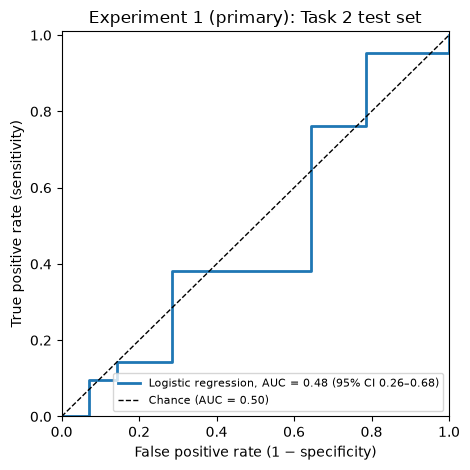

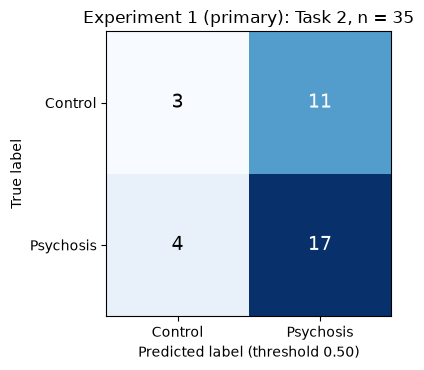

In [5]:
primary = fits["primary_110"][1]
fpr, tpr, _ = roc_curve(primary.true_label, primary.probability_psychosis)
row = metrics.set_index("analysis_version").loc["primary_110"]

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot(fpr, tpr, lw=2, label=f"Logistic regression, AUC = {row.roc_auc:.2f} "
                              f"(95% CI {row.roc_auc_ci_low:.2f}–{row.roc_auc_ci_high:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.50)")
ax.set(xlabel="False positive rate (1 − specificity)", ylabel="True positive rate (sensitivity)",
       title="Experiment 1 (primary): Task 2 test set", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / "primary_roc_curve.png", dpi=150)
plt.show()

matrix = confusion_matrix(primary.true_label, primary.predicted_label, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(matrix, cmap="Blues")
for (i, j), n in np.ndenumerate(matrix):
    ax.text(j, i, n, ha="center", va="center", fontsize=14,
            color="white" if n > matrix.max() / 2 else "black")
ax.set_xticks([0, 1], ["Control", "Psychosis"])
ax.set_yticks([0, 1], ["Control", "Psychosis"])
ax.set(xlabel="Predicted label (threshold 0.50)", ylabel="True label",
       title=f"Experiment 1 (primary): Task 2, n = {matrix.sum()}")
fig.tight_layout()
fig.savefig(OUTPUT / "primary_confusion_matrix.png", dpi=150)
plt.show()

## 4. Save outputs and summary

The summary text below is generated from the computed metrics, so it always matches them. The point estimate alone is not taken as evidence of above-chance discrimination; the conclusion depends on whether the 95% interval includes 0.50. The primary and sensitivity analyses differ in **both** their training and test participants (three recovered participants: one in training and two in testing), so any difference between them cannot be attributed only to the channel-omission change. The comparison only checks whether the overall conclusion depends on including those participants.

In [6]:
pd.concat([fits[a][1] for a in versions]).to_csv(OUTPUT / "test_predictions.csv", index=False)
metrics.to_csv(OUTPUT / "metrics.csv", index=False)

settings = {
    "research_question": "Can logistic regression trained on Task 1 distinguish first-episode psychosis from controls in Task 2?",
    "primary_hypothesis": "Task 2 ROC-AUC > 0.50",
    "features": FEATURES, "label_codes": LABEL_CODES, "train_dataset": TRAIN_DATASET, "test_dataset": TEST_DATASET,
    "pipeline": ["StandardScaler()", "LogisticRegression(l1_ratio=0.0 [pure L2], C=1.0, solver='lbfgs', max_iter=1000, class_weight=None)"],
    "threshold": THRESHOLD, "bootstrap": {"resamples": N_BOOTSTRAP, "stratified_by": "diagnosis", "random_seed": RANDOM_SEED,
                                          "interval": "percentile 2.5-97.5; fixed predictions; model not refitted"},
    "coefficients_standardized": {a: c for a, (_, _, c) in fits.items()},
    "input_sha256": {a: hashes for a, (_, _, hashes) in versions.items()},
    "versions": {"python": platform.python_version(),
                 **{p: version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib"]}},
}
(OUTPUT / "experiment_settings.json").write_text(json.dumps(settings, indent=2, default=float) + "\n")


def sentence(r):
    verdict = ("The interval includes 0.50, so these data do not show convincing above-chance discrimination."
               if r["ci_includes_0.5"] else
               "The interval lies entirely above 0.50, which supports above-chance discrimination in this test sample."
               if r.roc_auc_ci_low > 0.5 else
               "The interval lies entirely below 0.50, i.e. worse than chance in this test sample.")
    return (f"Test ROC-AUC = {r.roc_auc:.3f} (95% bootstrap CI {r.roc_auc_ci_low:.3f}–{r.roc_auc_ci_high:.3f}; "
            f"train n = {r.train_n}, test n = {r.test_n}: {r.test_control} controls, {r.test_psychosis} psychosis). "
            f"{verdict} At threshold 0.50: accuracy {r.accuracy:.3f}, sensitivity {r.sensitivity:.3f}, "
            f"specificity {r.specificity:.3f}, F1 {r.f1_psychosis:.3f} "
            f"(TN {r.true_negative}, FP {r.false_positive}, FN {r.false_negative}, TP {r.true_positive}).")


m = metrics.set_index("analysis_version")
same = m["ci_includes_0.5"].nunique() == 1
summary = "\n".join([
    "# Experiment 1 results summary", "",
    "Logistic regression (standardized relative delta, theta, alpha and beta power) trained on Task 1 and tested once on Task 2.", "",
    "## Primary analysis (frozen 110-participant preprocessing)", sentence(m.loc["primary_110"]), "",
    "## Sensitivity analysis (original 107-participant preprocessing)", sentence(m.loc["sensitivity_baseline_107"]), "",
    ("The two versions lead to the same conclusion about whether the interval includes 0.50."
     if same else "The two versions lead to different conclusions about whether the interval includes 0.50."),
    "Training and test samples both differ between versions, so a difference cannot be attributed only to channel omission. "
    "The 110-participant version remains the primary analysis.", "",
    "## Limitations",
    "- The CI reflects test-sample uncertainty for the fitted model only, not training-sample uncertainty.",
    f"- Threshold metrics should be compared with always predicting psychosis (Task 2 majority class: accuracy "
    f"{m.loc['primary_110'].test_psychosis / m.loc['primary_110'].test_n:.3f}). The primary model predicted psychosis for "
    f"{int(m.loc['primary_110'].true_positive + m.loc['primary_110'].false_positive)} of {int(m.loc['primary_110'].test_n)} "
    "participants, consistent with the Task 1 class balance and no class weighting.",
    "- Small test set (35 participants), and uneven exclusions (Task 1 8.5%, Task 2 42.6%), so retained participants may not represent the full cohorts.",
    "- Three recovered participants use 48 channels (one isolated bad channel omitted) instead of 49.",
    "- No shared IDs, but person-level independence of the two datasets is unconfirmed; Task 1 includes ten acquisition-2 participants.",
    "- The four relative powers sum to one, so coefficients are not independent biological effects.",
    "- This is a research analysis, not a clinically validated diagnostic tool.",
])
(OUTPUT / "results_summary.md").write_text(summary + "\n")
display(Markdown(summary))
print("Saved to", OUTPUT)

# Experiment 1 results summary

Logistic regression (standardized relative delta, theta, alpha and beta power) trained on Task 1 and tested once on Task 2.

## Primary analysis (frozen 110-participant preprocessing)
Test ROC-AUC = 0.476 (95% bootstrap CI 0.262–0.684; train n = 75, test n = 35: 14 controls, 21 psychosis). The interval includes 0.50, so these data do not show convincing above-chance discrimination. At threshold 0.50: accuracy 0.571, sensitivity 0.810, specificity 0.214, F1 0.694 (TN 3, FP 11, FN 4, TP 17).

## Sensitivity analysis (original 107-participant preprocessing)
Test ROC-AUC = 0.485 (95% bootstrap CI 0.267–0.684; train n = 74, test n = 33: 14 controls, 19 psychosis). The interval includes 0.50, so these data do not show convincing above-chance discrimination. At threshold 0.50: accuracy 0.606, sensitivity 0.789, specificity 0.357, F1 0.698 (TN 5, FP 9, FN 4, TP 15).

The two versions lead to the same conclusion about whether the interval includes 0.50.
Training and test samples both differ between versions, so a difference cannot be attributed only to channel omission. The 110-participant version remains the primary analysis.

## Limitations
- The CI reflects test-sample uncertainty for the fitted model only, not training-sample uncertainty.
- Threshold metrics should be compared with always predicting psychosis (Task 2 majority class: accuracy 0.600). The primary model predicted psychosis for 28 of 35 participants, consistent with the Task 1 class balance and no class weighting.
- Small test set (35 participants), and uneven exclusions (Task 1 8.5%, Task 2 42.6%), so retained participants may not represent the full cohorts.
- Three recovered participants use 48 channels (one isolated bad channel omitted) instead of 49.
- No shared IDs, but person-level independence of the two datasets is unconfirmed; Task 1 includes ten acquisition-2 participants.
- The four relative powers sum to one, so coefficients are not independent biological effects.
- This is a research analysis, not a clinically validated diagnostic tool.

Saved to /Users/akhil/Documents/nsci270-final/outputs/experiment_1
